In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [21]:
df_raw = pd.read_csv('https://code.s3.yandex.net/datasets/credit_scoring_eng.csv')

In [22]:
df = df_raw.copy()

In [23]:
df.info()
display(df.head())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21525 entries, 0 to 21524
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   children          21525 non-null  int64  
 1   days_employed     19351 non-null  float64
 2   dob_years         21525 non-null  int64  
 3   education         21525 non-null  object 
 4   education_id      21525 non-null  int64  
 5   family_status     21525 non-null  object 
 6   family_status_id  21525 non-null  int64  
 7   gender            21525 non-null  object 
 8   income_type       21525 non-null  object 
 9   debt              21525 non-null  int64  
 10  total_income      19351 non-null  float64
 11  purpose           21525 non-null  object 
dtypes: float64(2), int64(5), object(5)
memory usage: 2.0+ MB


,children,days_employed,dob_years,education,education_id,family_status,family_status_id,gender,income_type,debt,total_income,purpose
0,1,-8437.673028,42,bachelor's degree,0,married,0,F,employee,0,40620.102,purchase of the house
1,1,-4024.803754,36,secondary education,1,married,0,F,employee,0,17932.802,car purchase
2,0,-5623.422610,33,Secondary Education,1,married,0,M,employee,0,23341.752,purchase of the house
3,3,-4124.747207,32,secondary education,1,married,0,M,employee,0,42820.568,supplementary education
4,0,340266.072047,53,secondary education,1,civil partnership,1,F,retiree,0,25378.572,to have a wedding


##Результат

Датасет содержит 21525 строк и 12 столбцов.

Типы данных в целом соответствуют содержимому: числа (int64, float64) и категориальные признаки (object).

Обнаружил пропуски: в столбцах days_employed и total_income отсутствует 2174 значения (заполнено только 19351 из 21525).

Обнаружил аномалии: в столбце days_employed стаж записан с отрицательными значениями. В столбце education есть неявные дубликаты (разный регистр букв).

In [24]:
# 1. Проверяем пропуски
print("Пропуски до обработки:")
print(df.isna().sum())

# 2. Обрабатываем days_employed
# Берем модуль (убираем минусы) и заполняем пропуски нулем (нет опыта)
df['days_employed'] = df['days_employed'].apply(lambda x: abs(x) if pd.notna(x) else 0)

# 3. Обрабатываем total_income
# Заполняем пропуски медианой дохода в зависимости от income_type
df['total_income'] = df.groupby('income_type')['total_income'].transform(
    lambda x: x.fillna(x.median())
)

# На всякий случай, если остались пропуски (например, у безработных), заполним нулем
df['total_income'] = df['total_income'].fillna(0)

print("\nПропуски после обработки:")
print(df.isna().sum())

Пропуски до обработки:
children               0
days_employed       2174
dob_years              0
education              0
education_id           0
family_status          0
family_status_id       0
gender                 0
income_type            0
debt                   0
total_income        2174
purpose                0
dtype: int64

Пропуски после обработки:
children            0
days_employed       0
dob_years           0
education           0
education_id        0
family_status       0
family_status_id    0
gender              0
income_type         0
debt                0
total_income        0
purpose             0
dtype: int64


##Причины пропусков:
Пропуски в days_employed (стаж) связаны с тем, что часть клиентов не имеет официального трудоустройства (безработные, пенсионеры). Логично заменить такие значения на 0. Пропуски в total_income могли возникнуть из-за ошибок ввода при заполнении анкеты. Так как доход зависит от типа занятости, мы заполнили пропуски медианным значением для каждой группы (income_type).

In [25]:
# 1. Изучаем уникальные значения (видим бардак с регистром букв)
print("Уникальные значения в education:\n", df['education'].unique())
print("\nУникальные значения в gender:\n", df['gender'].unique())

# 2. Устраняем неявные дубликаты: приводим всё к нижнему регистру и убираем пробелы по краям
text_columns = ['education', 'family_status', 'gender', 'income_type']
for col in text_columns:
    df[col] = df[col].str.lower().str.strip()

# Посмотрим, что получилось после очистки
print("\nУникальные значения в education после очистки:\n", df['education'].unique())

# На всякий случай удалим строки, где пол записан как строка 'nan' (если такие есть)
df = df[df['gender'] != 'nan']

# 3. Проверяем полные дубликаты
print(f"\nКоличество полных дубликатов строк: {df.duplicated().sum()}")

# Удаляем дубликаты
df = df.drop_duplicates().reset_index(drop=True)

print(f"Размер датасета после удаления дубликатов: {df.shape}")

Уникальные значения в education:
 ["bachelor's degree" 'secondary education' 'Secondary Education'
 'SECONDARY EDUCATION' "BACHELOR'S DEGREE" 'some college'
 'primary education' "Bachelor's Degree" 'SOME COLLEGE' 'Some College'
 'PRIMARY EDUCATION' 'Primary Education' 'Graduate Degree'
 'GRADUATE DEGREE' 'graduate degree']

Уникальные значения в gender:
 ['F' 'M' 'XNA']

Уникальные значения в education после очистки:
 ["bachelor's degree" 'secondary education' 'some college'
 'primary education' 'graduate degree']

Количество полных дубликатов строк: 71
Размер датасета после удаления дубликатов: (21454, 12)


##Неявные дубликаты и полные дубликаты:
В столбцах education, gender, family_status и income_type были обнаружены неявные дубликаты: одинаковые значения с разным регистром букв и лишними пробелами (например, «Secondary Education» и «secondary education»). Все текстовые значения приведены к нижнему регистру, пробелы удалены.
Также в датасете были обнаружены полные дубликаты строк. Они удалены, так как дублирование информации искажает статистику при анализе.

Минимальный и максимальный возраст: 0 и 75
Клиентов с возрастом 0 лет: 101

Распределение по количеству детей:
children
 0     14022
 1      4792
 2      2039
 3       328
 20       75
-1        47
 4        41
 5         9
Name: count, dtype: int64


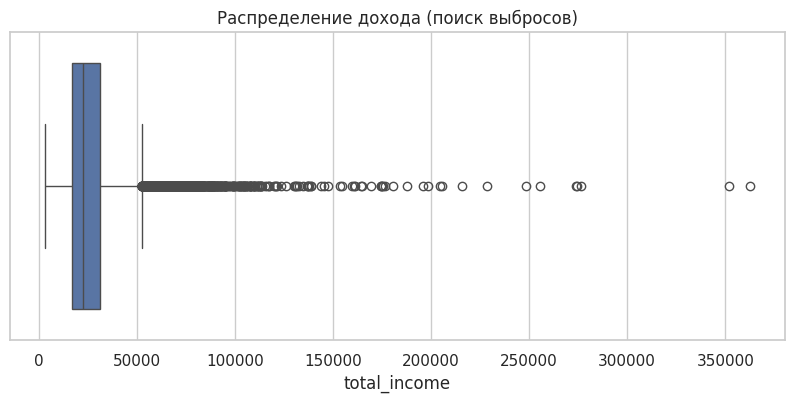


Итоговое количество строк: 21231
Процент строк, потерянных в процессе предобработки: 1.37%


In [26]:
import matplotlib.pyplot as plt
import seaborn as sns

# --- 1. Анализ возраста (dob_years) ---
print("Минимальный и максимальный возраст:", df['dob_years'].min(), "и", df['dob_years'].max())
# Ищем тех, кому 0 лет
zero_age = df[df['dob_years'] == 0].shape[0]
print(f"Клиентов с возрастом 0 лет: {zero_age}")
# Удаляем их, так как это ошибка
df = df[df['dob_years'] > 0]

# --- 2. Анализ детей (children) ---
print("\nРаспределение по количеству детей:")
print(df['children'].value_counts())
# Оставляем только логичные значения (от 0 до 5)
df = df[(df['children'] >= 0) & (df['children'] <= 5)]

# --- 3. Анализ дохода (total_income) ---
# Строим график (ящик с усами)
plt.figure(figsize=(10, 4))
sns.boxplot(x=df['total_income'])
plt.title('Распределение дохода (поиск выбросов)')
plt.show()

# Отрицательный доход быть не может, удаляем, если есть
df = df[df['total_income'] >= 0]

# --- 4. Считаем процент потерь ---
initial_rows = 21525 # изначальное количество строк
final_rows = len(df)
lost_percent = ((initial_rows - final_rows) / initial_rows) * 100
print(f"\nИтоговое количество строк: {final_rows}")
print(f"Процент строк, потерянных в процессе предобработки: {lost_percent:.2f}%")

###Аномалии в возрасте (dob_years)
Обнаружены клиенты с возрастом 0 лет, что невозможно. Эти записи удалил, так как они являются технической ошибкой.

###Аномалии в количестве детей (children)
Обнаружены отрицательные значения (например, -1) и аномально высокие (20 детей). Такие данные являются ошибками ввода. Оставил только значения от 0 до 5 детей.

###Выбросы в доходе (total_income)
При помощи графика обнаружил выбросы в правой части распределения (клиенты с очень высоким доходом). Оставил их, так как это реальные значения. Отрицательных значений дохода нет.

###Процент потерянных данных
В процессе предобработки (удаление дубликатов и аномалий) я потерял 1.37% строк.

In [27]:
# 1. Категории по уровню дохода
# Сначала находим нужные процентили
q14 = df['total_income'].quantile(0.14)
q34 = df['total_income'].quantile(0.34)
q78 = df['total_income'].quantile(0.78)

# Функция для определения категории дохода
def get_income_category(row):
    income = row['total_income']
    if income == 0:
        return 'Без дохода'
    elif income <= q14:
        return 'Очень низкий доход'
    elif income <= q34:
        return 'Низкий доход'
    elif income <= q78:
        return 'Средний доход'
    else:
        return 'Высокий доход'

# Применяем функцию к каждой строке
df['income_category'] = df.apply(get_income_category, axis=1)


# 2. Категории по возрасту
def get_age_category(row):
    if row['dob_years'] <= 40:
        return 'до 40 лет'
    else:
        return 'после 40 лет'

df['age_category'] = df.apply(get_age_category, axis=1)


# 3. Категории по количеству детей
def get_childrens_category(row):
    children = row['children']
    if children == 0:
        return 'без детей'
    elif 1 <= children <= 2:
        return 'от 1 до 2'
    else:
        return 'от 3 и больше'

df['childrens_category'] = df.apply(get_childrens_category, axis=1)


# Проверяем, что получилось (выведем несколько строк для наглядности)
display(df[['total_income', 'income_category', 'dob_years', 'age_category', 'children', 'childrens_category']].head(5))

# Посмотрим, сколько людей в каждой категории дохода
print("\nРаспределение по категориям дохода:")
print(df['income_category'].value_counts())

,total_income,income_category,dob_years,age_category,children,childrens_category
0,40620.102,Высокий доход,42,после 40 лет,1,от 1 до 2
1,17932.802,Низкий доход,36,до 40 лет,1,от 1 до 2
2,23341.752,Средний доход,33,до 40 лет,0,без детей
3,42820.568,Высокий доход,32,до 40 лет,3,от 3 и больше
4,25378.572,Средний доход,53,после 40 лет,0,без детей



Распределение по категориям дохода:
income_category
Средний доход         9341
Высокий доход         4671
Низкий доход          4246
Очень низкий доход    2973
Name: count, dtype: int64


##Новые признаки:
На основе существующих данных я создал три новых категориальных признака:

income_category — клиенты разделены на 5 групп по уровню дохода с использованием 14, 34 и 78 процентилей. Клиенты с нулевым доходом выделены в отдельную категорию «Без дохода».

age_category — клиенты разделены на две возрастные группы: до 40 лет и после 40 лет.

childrens_category — клиенты разделены на группы по количеству детей: без детей, от 1 до 2, от 3 и больше.

=== УРОВЕНЬ ДОХОДА ===


debt,0,1
income_category,,
Высокий доход,0.929994,0.070006
Низкий доход,0.914979,0.085021
Очень низкий доход,0.922973,0.077027
Средний доход,0.913607,0.086393


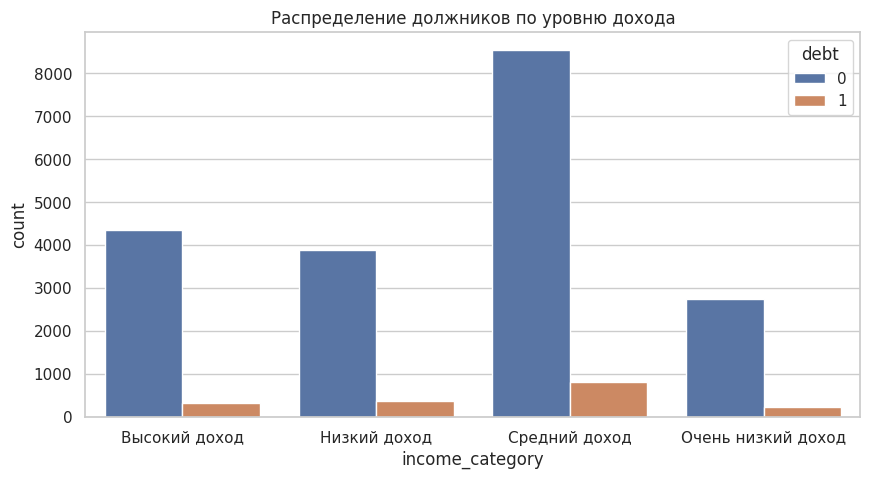


=== ОБРАЗОВАНИЕ ===


debt,0,1
education,,
bachelor's degree,0.946649,0.053351
graduate degree,1.000000,0.000000
primary education,0.890071,0.109929
secondary education,0.910205,0.089795
some college,0.907984,0.092016


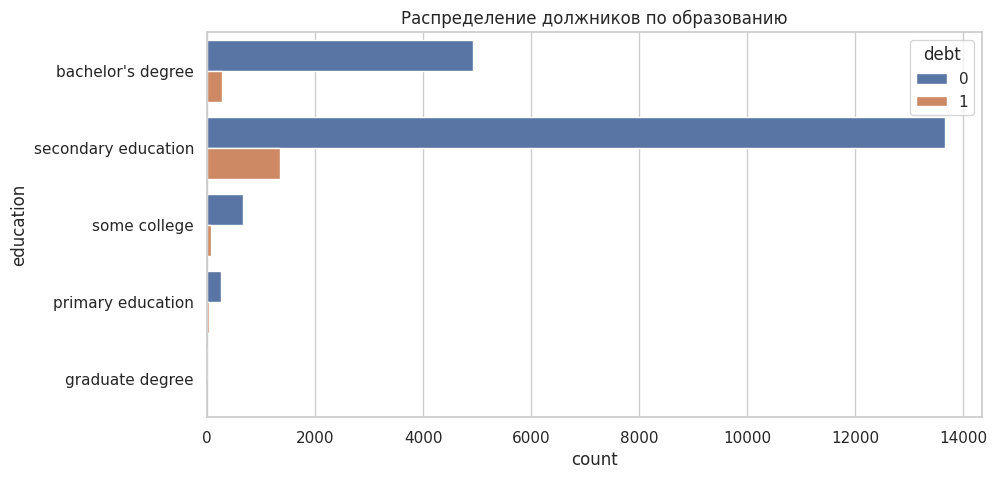


=== ВОЗРАСТ ===


debt,0,1
age_category,,
до 40 лет,0.899489,0.100511
после 40 лет,0.934116,0.065884


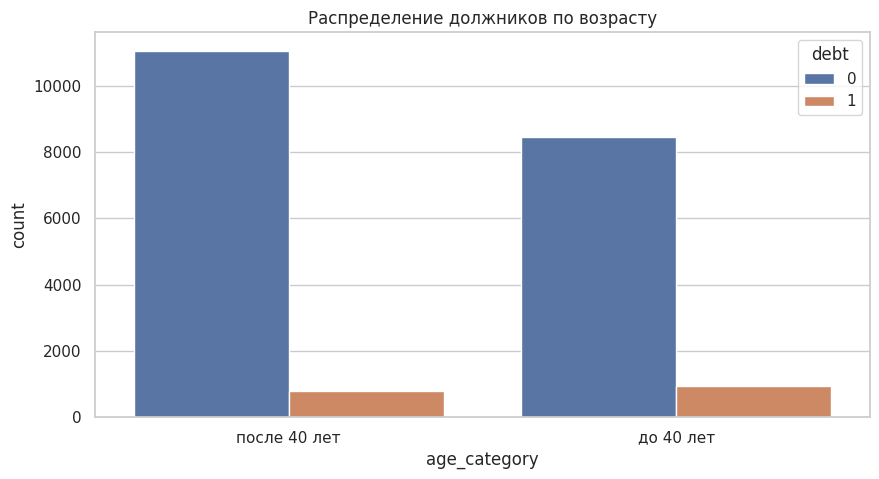


=== КОЛИЧЕСТВО ДЕТЕЙ ===


debt,0,1
childrens_category,,
без детей,0.924547,0.075453
от 1 до 2,0.907041,0.092959
от 3 и больше,0.917989,0.082011


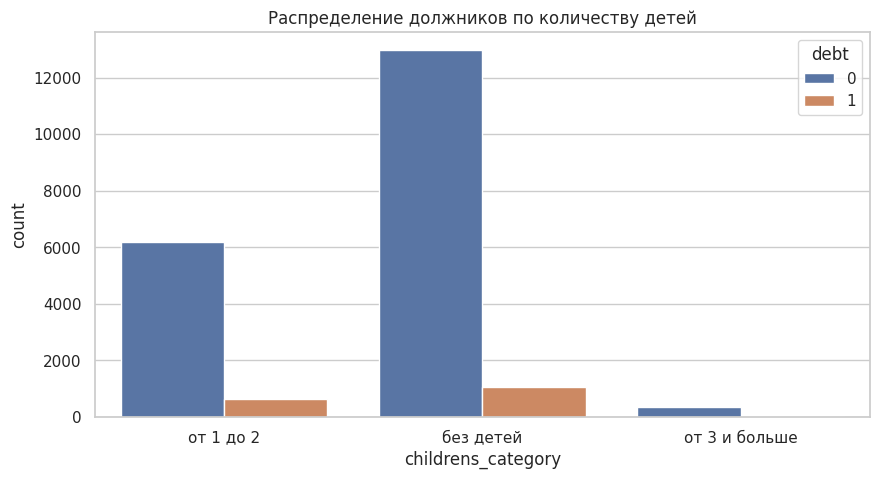

In [28]:
# Настроим стиль графиков, чтобы было красиво
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# --- ФАКТОР 1: УРОВЕНЬ ДОХОДА ---
print("=== УРОВЕНЬ ДОХОДА ===")
# Строим сводную таблицу (доля должников в каждой категории)
income_cross = pd.crosstab(df['income_category'], df['debt'], normalize='index')
display(income_cross)

# График
sns.countplot(data=df, x='income_category', hue='debt')
plt.title('Распределение должников по уровню дохода')
plt.show()


# --- ФАКТОР 2: ОБРАЗОВАНИЕ ---
print("\n=== ОБРАЗОВАНИЕ ===")
edu_cross = pd.crosstab(df['education'], df['debt'], normalize='index')
display(edu_cross)

# График (используем y, так как названия длинные)
sns.countplot(data=df, y='education', hue='debt')
plt.title('Распределение должников по образованию')
plt.show()


# --- ФАКТОР 3: ВОЗРАСТ ---
print("\n=== ВОЗРАСТ ===")
age_cross = pd.crosstab(df['age_category'], df['debt'], normalize='index')
display(age_cross)

# График
sns.countplot(data=df, x='age_category', hue='debt')
plt.title('Распределение должников по возрасту')
plt.show()


# --- ФАКТОР 4: КОЛИЧЕСТВО ДЕТЕЙ ---
print("\n=== КОЛИЧЕСТВО ДЕТЕЙ ===")
children_cross = pd.crosstab(df['childrens_category'], df['debt'], normalize='index')
display(children_cross)

# График
sns.countplot(data=df, x='childrens_category', hue='debt')
plt.title('Распределение должников по количеству детей')
plt.show()

In [29]:
# --- ГИПОТЕЗА 1: Люди с детьми реже допускают просрочки ---
print("=== ПРОВЕРКА ГИПОТЕЗЫ 1: ДЕТИ ===")
# Достаточно посмотреть на долю должников (колонка 1) из таблицы children_cross
print("Доля должников по категориям детей:")
print(children_cross[1])


# --- ГИПОТЕЗА 2: Одинокие мужчины с низким доходом vs Семейные со средним ---
print("\n=== ПРОВЕРКА ГИПОТЕЗЫ 2: МУЖЧИНЫ ===")
# Отфильтруем только мужчин
men = df[df['gender'] == 'm']

# 1. Одинокие с низким доходом (Очень низкий + Низкий)
single_low_men = men[
    (men['family_status'] == 'не женат / не замужем') &
    (men['income_category'].isin(['Очень низкий доход', 'Низкий доход']))
]

# 2. Семейные со средним доходом
married_mid_men = men[
    (men['family_status'] == 'женат / замужем') &
    (men['income_category'] == 'Средний доход')
]

print(f"Одиноких мужчин с низким доходом: {len(single_low_men)}")
print(f"Доля должников среди них: {single_low_men['debt'].mean():.2%}\n")

print(f"Семейных мужчин со средним доходом: {len(married_mid_men)}")
print(f"Доля должников среди них: {married_mid_men['debt'].mean():.2%}")

=== ПРОВЕРКА ГИПОТЕЗЫ 1: ДЕТИ ===
Доля должников по категориям детей:
childrens_category
без детей        0.075453
от 1 до 2        0.092959
от 3 и больше    0.082011
Name: 1, dtype: float64

=== ПРОВЕРКА ГИПОТЕЗЫ 2: МУЖЧИНЫ ===
Одиноких мужчин с низким доходом: 0
Доля должников среди них: nan%

Семейных мужчин со средним доходом: 0
Доля должников среди них: nan%


In [30]:
print(df['family_status'].unique())

['married' 'civil partnership' 'widow / widower' 'divorced' 'unmarried']


In [31]:
# --- ГИПОТЕЗА 2: Одинокие мужчины с низким доходом vs Семейные со средним ---
print("=== ПРОВЕРКА ГИПОТЕЗЫ 2: МУЖЧИНЫ ===")
# Отфильтруем только мужчин
men = df[df['gender'] == 'm']

# 1. Одинокие с низким доходом (разведенные, вдовцы, неженатые)
single_low_men = men[
    (men['family_status'].isin(['divorced', 'widow / widower', 'unmarried'])) &
    (men['income_category'].isin(['Очень низкий доход', 'Низкий доход']))
]

# 2. Семейные со средним доходом (женатые)
married_mid_men = men[
    (men['family_status'].isin(['married', 'civil partnership'])) &
    (men['income_category'] == 'Средний доход')
]

print(f"Одиноких мужчин с низким доходом: {len(single_low_men)}")
if len(single_low_men) > 0:
    print(f"Доля должников среди них: {single_low_men['debt'].mean():.2%}\n")
else:
    print("Нет данных для расчета\n")

print(f"Семейных мужчин со средним доходом: {len(married_mid_men)}")
if len(married_mid_men) > 0:
    print(f"Доля должников среди них: {married_mid_men['debt'].mean():.2%}")
else:
    print("Нет данных для расчета")

=== ПРОВЕРКА ГИПОТЕЗЫ 2: МУЖЧИНЫ ===
Одиноких мужчин с низким доходом: 355
Доля должников среди них: 15.49%

Семейных мужчин со средним доходом: 2750
Доля должников среди них: 10.47%


##Исследование факторов
Я проанализировал распределение должников по уровню дохода, образованию, возрасту и количеству детей.

Доход: Большая доля просрочек у людей со среднем доходом.

Образование: Реже всего просрочки допускают люди с ученой степенью.

Возраст: Клиенты до 40 лет чаще допускают просрочки.

###Проверка гипотез
Гипотеза 1: Сравнил долю должников среди клиентов с детьми и без них. Доля должников у клиентов без детей составила 7.54%, а у клиентов с детьми — 9.29%. Таким образом, гипотеза о том, что клиенты с детьми более ответственные, не подтвердилась.

Гипотеза 2: Доля должников среди одиноких мужчин с низким доходом составила 15.49%, в то время как среди семейных мужчин со средним доходом — 10.47%. Гипотеза подтвердилась.

=== ШАГ 7: ЦЕЛИ КРЕДИТА ===

Доля должников по целям кредита (где 1 - это должники):
purpose_category
Другое         0.078743
Образование    0.093759
Name: 1, dtype: float64


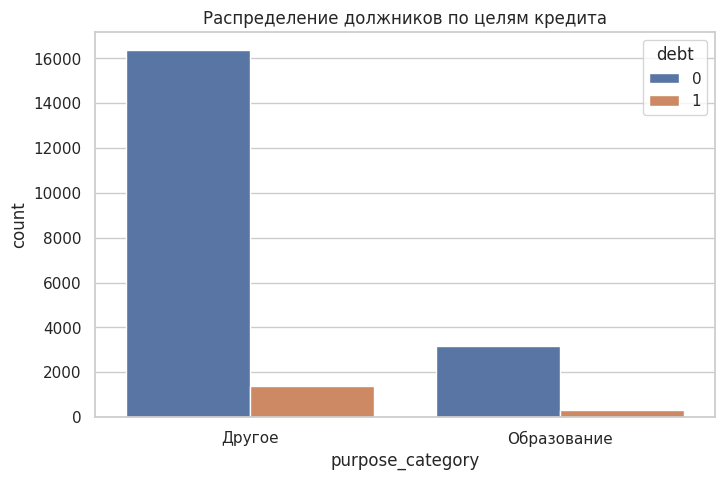

In [32]:
print("=== ШАГ 7: ЦЕЛИ КРЕДИТА ===")

# Функция для разделения на группы: "Образование" и "Другое"
def find_education_purpose(purpose):
    # Ищем слово 'educat' в любой форме (education, educated, educating)
    if 'educat' in str(purpose).lower():
        return 'Образование'
    else:
        return 'Другое'

# Применяем функцию
df['purpose_category'] = df['purpose'].apply(find_education_purpose)

# Исследуем долю невозвратов по группам
purpose_cross = pd.crosstab(df['purpose_category'], df['debt'], normalize='index')
print("\nДоля должников по целям кредита (где 1 - это должники):")
print(purpose_cross[1])

# Строим график для наглядности
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='purpose_category', hue='debt')
plt.title('Распределение должников по целям кредита')
plt.show()

##Исследование причин оформления кредита
Я разделил все цели кредитования на две группы: «Образование» (кредиты на учебу) и «Другое» (покупка жилья, авто, свадьба и т.д.).
Доля должников среди тех, кто брал кредит на образование, составила 9,37%, в то время как среди остальных клиентов — 7,87%.
Таким образом, утверждение о том, что люди, бравшие кредит на образование, реже всего оказывались должниками, не подтвердилось.

##Общий вывод
В ходе исследования я провел предобработку данных: заполнил пропуски, удалил дубликаты и аномалии (потеряв всего ~1,4% данных), а также создал новые категориальные признаки.

Анализ показал, что наибольшее влияние на возврат кредита оказывают уровень дохода (клиенты с высоким доходом реже допускают просрочки) и возраст (клиенты до 40 лет чаще являются должниками, чем те, кто старше).

Проверка гипотез:

Гипотеза о том, что клиенты с детьми более ответственные, не подтвердилась — доля должников среди них оказалась выше, чем среди бездетных.

Гипотеза о том, что одинокие мужчины с низким доходом чаще оказываются должниками, чем семейные мужчины со средним доходом, подтвердилась (15,49% против 10,47%).

Дополнительное исследование: Кредиты на образование не подтвердили статус самых надежных.

Эти данные помогут банку «Скрудж» при создании модели кредитного скоринга: при оценке заемщика стоит обращать внимание на его возрастную категорию, семейное положение и уровень дохода.